# Les déserts de carburant en France

*Projet réalisé par Aurélien Quisefit et François Moussinga*

## Introduction

### Contexte

En dehors des grandes villes, la voiture est quasiment le seul moyen de se déplacer : aller travailler, faire ses courses ou amener ses enfants à l'école suppose de pouvoir faire le plein. Or, le réseau de stations-service s'est fortement réduit depuis plusieurs décennies. Les petites stations indépendantes ferment faute de rentabilité, et l'offre se concentre dans les grandes surfaces et le long des axes principaux. Aujourd'hui, environ 10 000 stations publient leurs prix en France métropolitaine, pour près de 35 000 communes.

En outre, le prix des carburants est devenu un sujet politique sensible, autour de 2 €/L pour le gazole. On pense ici aux manifestations des gilets jaunes. Ce sujet est d'ailleurs revenu le mois dernier dans les manifestations, rejoignant le mouvement lycéen. Pour les ménages ruraux, il pèse d'autant plus que les distances parcourues sont longues.

On appelle ici **« désert de carburant »** une commune éloignée de toute station-service. Ses habitants doivent faire un détour pour faire le plein et ont peu de choix entre les stations.

### Problématique

**Les habitants des déserts de carburant sont-ils désavantagés, et pourquoi ces déserts existent-ils ? La concurrence locale fait-elle le prix à la pompe ?**

On teste en particulier trois hypothèses :
1. **Où sont les déserts ?** Ils s'expliqueraient par la faible densité de population et par le relief.
2. **Les habitants paient-ils plus cher ?** Avec peu de concurrence à proximité, les stations isolées pourraient pratiquer des prix plus élevés.
3. **La concurrence fait-elle le prix ?** Les stations entourées de plus de concurrents affichent-elles des prix plus bas, à caractéristiques comparables ? C'est la question centrale du projet, traitée en section 7.

### Données

- **Le flux officiel des prix des carburants** (donnees.roulez-eco.fr) : les stations-service ont l'obligation légale de déclarer leurs prix. Le flux donne la position de chaque station et ses prix par carburant.
- **L'API Géo** (geo.api.gouv.fr) : la position, la population et la superficie de chaque commune.

Ces données sont *instantanées* : en relançant le notebook un autre jour, les chiffres varient légèrement, mais les conclusions restent les mêmes.

### Plan

1. Collecte et nettoyage des données sur les stations et les prix
2. Calcul de la distance entre chaque commune et la station la plus proche
3. Définition d'un seuil de désert et repérage sur le territoire
4. Les habitants des déserts paient-ils plus cher ?
5. Les déserts selon la densité et le département
6. Conclusion et limites

## 1. Données et nettoyage


On commence par importer les bibliothèques importantes. Puis on va chercher les données sur Internet (source : donnees.roulez-eco.fr). Elles sont disponibles car les stations-service ont l'obligation légale de publier leurs données. Par contre, les données sont instantanées. Le flux n'est pas une série temporelle : un téléchargement une semaine plus tard ne donnera pas exactement le même résultat. On vérifie que l'importation s'est bien passée puis on ouvre le zip et on lit le XML qui est dedans. On obtient 9825 observations de stations-service. 

In [1]:
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import seaborn as sns

import fonctions

In [2]:
# Les sections 6 à 11 s'appuient sur des caches locaux (voir la section « Données locales » du README) :
# on vérifie leur présence avant de calculer.
import json
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / 'src').exists():  # notebook lancé depuis notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))

from carburants import config as C
from carburants.analysis import add_departement_gap, ols_hc1, r_carre
from carburants.competition import distance_grande_surface, fuel_competition, mediane_ponderee, part_population_dans_rayon
from carburants.geo import nearest_k
from carburants.panel import load_snapshot_prices, snapshot_coverage, temporal_feasibility
from carburants.storage import storage_from_env
from IPython.display import Image, Markdown, display

caches = {'enseignes (OSM)': C.OSM_MATCH_PARQUET, 'grandes surfaces (OSM)': C.GS_PARQUET,
          'revenu communal (Filosofi)': C.COMMUNES_PARQUET}
manquants = [nom for nom, chemin in caches.items() if not chemin.exists()]
if manquants:
    raise FileNotFoundError(f"Caches absents : {manquants}. Voir la section « Données locales » du README.")
print("Caches trouvés.")

Caches trouvés.


In [3]:
df_stations, df_prix = fonctions.telecharger_stations_et_prix()
print(len(df_stations), "stations et", len(df_prix), "prix")

9825 stations et 33110 prix


On sépare le XML en deux tableaux, un pour les stations (position, etc.) et un autre pour les prix. Cela nous permet d'éviter les répétitions de lignes.

In [4]:
df_prix.head()

,id,carburant,valeur,maj
0,56580001,Gazole,2.109,2026-11-12 06:55:20
1,56580001,SP95,2.009,2026-11-12 06:55:20
2,56580001,SP98,2.049,2026-11-12 06:55:21
3,89100001,Gazole,2.099,2026-11-23 14:35:41
4,89100001,E85,0.869,2026-11-10 09:49:38


On normalise les degrés de longitude et de latitude pour avoir les bonnes conventions de valeurs et on ne sélectionne que les stations en métropole (en réalité, on n'exclut aucune station donc toutes nos stations l'étaient déjà). Ensuite, on exclut les valeurs aberrantes (il n'y en avait pas) et on enlève les prix périmés (on considère qu'un prix non actualisé depuis plus de 7 jours n'est plus pratiqué la plupart du temps). 

In [5]:
df_stations["latitude"] = pd.to_numeric(df_stations["latitude"], errors="coerce") / 100_000
df_stations["longitude"] = pd.to_numeric(df_stations["longitude"], errors="coerce") / 100_000
df_stations["departement"] = df_stations["cp"].str[:2]

# On garde la France métropolitaine (Corse comprise) grâce à un rectangle de coordonnées
en_metropole = (
    df_stations["latitude"].between(41, 51.5)
    & df_stations["longitude"].between(-5.5, 10)
)
print("Stations hors métropole ou sans coordonnées :", (~en_metropole).sum())
df_stations = df_stations[en_metropole].copy()
print("Stations conservées :", len(df_stations))

Stations hors métropole ou sans coordonnées : 0
Stations conservées : 9825


In [6]:
df_prix["valeur"] = pd.to_numeric(df_prix["valeur"], errors="coerce")
df_prix["maj"] = pd.to_datetime(df_prix["maj"], errors="coerce")

prix_plausible = df_prix["valeur"].between(0.5, 3.5)
date_reference = df_prix["maj"].max()
prix_recent = df_prix["maj"] >= date_reference - pd.Timedelta(days=7)

print("Prix hors de [0,50 ; 3,50] €/L :", (~prix_plausible).sum())
print("Prix de plus de 7 jours :", (~prix_recent).sum())

df_prix = df_prix[prix_plausible & prix_recent & df_prix["id"].isin(df_stations["id"])].copy()
print("Prix conservés :", len(df_prix))
df_prix.groupby("carburant")["valeur"].describe()

Prix hors de [0,50 ; 3,50] €/L : 0
Prix de plus de 7 jours : 6007
Prix conservés : 27103


,count,mean,std,min,25%,50%,75%,max
carburant,,,,,,,,
E10,6798.0,1.946098,0.075914,1.339,1.898,1.9310,1.989,2.990
E85,2592.0,0.896351,0.072312,0.659,0.858,0.8845,0.919,2.019
GPLc,895.0,1.086857,0.073674,0.866,1.023,1.0870,1.149,1.394
Gazole,8252.0,2.103497,0.088881,1.833,2.029,2.0850,2.172,2.530
SP95,2056.0,2.007147,0.070484,1.858,1.965,1.9900,2.029,2.380
SP98,6510.0,2.045823,0.082258,1.862,1.990,2.0130,2.079,2.529


On importe maintenant les communes avec leur position, leur superficie et leur population car on a besoin de savoir où habitent les gens pour savoir s'ils sont plus ou moins loin des stations.

In [7]:
df_communes = fonctions.telecharger_communes()
print(df_communes.shape)
df_communes.head()

(34969, 7)


,code,nom,population,surface,codeDepartement,centre.type,centre.coordinates
0,01001,L'Abergement-Clémenciat,860.0,1564.50,01,Point,"[4.9306, 46.1517]"
1,01002,L'Abergement-de-Varey,270.0,919.01,01,Point,"[5.4247, 46.0071]"
2,01004,Ambérieu-en-Bugey,15934.0,2454.80,01,Point,"[5.3706, 45.9575]"
3,01005,Ambérieux-en-Dombes,1906.0,1603.97,01,Point,"[4.9119, 45.9992]"
4,01006,Ambléon,115.0,604.01,01,Point,"[5.5928, 45.7483]"


## 2. Communes et distances


On sépare en deux colonnes la longitude et la latitude. On convertit la surface en km². On retire les outre-mer (le tableau Prix ne les comprenait pas) et les communes sans population. On remarque que la commune médiane a 456 habitants et qu'on a 34746 communes pour 9825 stations.

In [8]:
df_communes["longitude"] = df_communes["centre.coordinates"].str[0]
df_communes["latitude"] = df_communes["centre.coordinates"].str[1]

df_communes["surface_km2"] = df_communes["surface"] / 100
df_communes["densite"] = df_communes["population"] / df_communes["surface_km2"]

en_metropole = (
    df_communes["latitude"].between(41, 51.5)
    & df_communes["longitude"].between(-5.5, 10)
)
avec_population = df_communes["population"].notna()
print("Communes retirées :", (~(en_metropole & avec_population)).sum())

df_communes = df_communes[en_metropole & avec_population].copy()
print("Communes conservées :", len(df_communes))
df_communes[["nom", "population", "surface_km2", "densite"]].describe()

Communes retirées : 223
Communes conservées : 34746


,population,surface_km2,densite
count,3.474600e+04,34746.000000,34746.000000
mean,1.904271e+03,15.799415,165.933598
std,1.490933e+04,17.356149,750.041526
min,0.000000e+00,0.028400,0.000000
25%,1.970000e+02,6.520025,18.199153
50%,4.560000e+02,10.978000,40.310795
75%,1.163000e+03,19.014775,96.828126
max,2.103778e+06,756.780100,28187.274910


On mesure la distance à vol d'oiseau faute de calculateur d'itinéraires (malheureusement, cela sous-estime le trajet réel, surtout en montagne). Pour éviter de comparer chaque commune à chaque station (≈ 341 millions de calculs), on utilise un BallTree, qui regroupe les stations par zones et élimine d'emblée les plus lointaines. On trouve que la distance médiane est de 4,7 km. Les extrêmes sont cohérents. Sentein et Antras sont dans les montagnes. Ouessant et Hœdic sont des îles. Ces deux cas posent une question : aucune station n'y est officiellement enregistrée, et le carburant y est vraisemblablement acheminé par bateau.

In [9]:
df_communes["distance_station_km"], df_communes["station_proche_id"] = (
    fonctions.distance_plus_proche(df_communes, df_stations)
)
print(df_communes["distance_station_km"].describe())

count    34746.000000
mean         4.975199
std          2.979277
min          0.013784
25%          2.745965
50%          4.653100
75%          6.736492
max         27.167184
Name: distance_station_km, dtype: float64


In [10]:
print("Communes les plus éloignées :")
print(
    df_communes
    .nlargest(10, "distance_station_km")[["nom", "codeDepartement", "population", "distance_station_km"]]
)

Communes les plus éloignées :
                        nom codeDepartement  population  distance_station_km
10377              Ouessant              29       860.0            27.167184
3086                Sentein              09       175.0            23.150883
20542                 Hœdic              56       104.0            21.756735
6869       Gurgy-le-Château              21        45.0            21.514817
2819                 Antras              09        74.0            21.174219
6818   Faverolles-lès-Lucey              21        29.0            20.695044
6689               Chambain              21        36.0            20.628464
6683             Buxerolles              21        34.0            20.313196
6868         Gurgy-la-Ville              21        26.0            20.186046
6914                  Lucey              21        56.0            19.996444


## 3. Déserts de carburant


On choisit a priori un seuil de 10 km pour le désert de carburant. On vérifie ensuite que ce seuil correspond à un quantile cohérent. En effet, seules 6 % des communes sont à plus de 10 km à vol d'oiseau d'une station, et seulement 1 % des habitants sont concernés car ces communes sont peu peuplées. Certes, cela ne représente que 1 % des habitants, mais cela fait quand même 636 000 personnes.

In [11]:
SEUIL_DESERT_KM = 10

df_communes["est_desert"] = df_communes["distance_station_km"] > SEUIL_DESERT_KM

nb_communes = df_communes["est_desert"].sum()
part_communes = 100 * df_communes["est_desert"].mean()
pop_desert = df_communes.loc[df_communes["est_desert"], "population"].sum()
part_pop = 100 * pop_desert / df_communes["population"].sum()

print(f"Communes en désert : {nb_communes} ({part_communes:.1f} %)")
print(f"Habitants concernés : {pop_desert:,.0f} ({part_pop:.1f} %)")

print("\nDistribution des distances :")
print(df_communes["distance_station_km"].quantile([0.5, 0.75, 0.9, 0.95, 0.99]))

Communes en désert : 2081 (6.0 %)
Habitants concernés : 636,124 (1.0 %)

Distribution des distances :
0.50     4.653100
0.75     6.736492
0.90     8.897535
0.95    10.361400
0.99    13.641910
Name: distance_station_km, dtype: float64


Ce seuil semble plutôt bien choisi.

In [12]:
for seuil in [5, 10, 15]:
    masque = df_communes["distance_station_km"] > seuil
    print(f"{seuil} km : {masque.sum()} communes, {df_communes.loc[masque, 'population'].sum():,.0f} habitants")

5 km : 15729 communes, 7,132,712 habitants
10 km : 2081 communes, 636,124 habitants
15 km : 171 communes, 27,503 habitants


On importe Seaborn pour obtenir un histogramme de la distribution des communes selon leur distance à une station. On trouve un mode à 5 km, et la plupart des communes sont à moins de 7 km d'une station. La distribution est asymétrique, ce qui est cohérent.

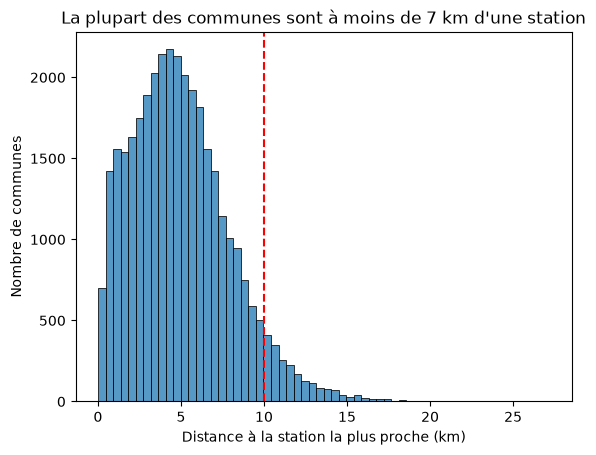

In [13]:
ax = sns.histplot(df_communes, x="distance_station_km", bins=60)
ax.axvline(SEUIL_DESERT_KM, color="red", linestyle="--")
ax.set(xlabel="Distance à la station la plus proche (km)",
       ylabel="Nombre de communes",
              title="La plupart des communes sont à moins de 7 km d'une station");

## 4. Relief et densité


Seaborn n'a pas été performant pour construire une carte avec des couleurs continues. On réutilise donc matplotlib (importé au début). Chaque point est une commune dont l'intensité de la couleur révèle sa distance à une station. On trouve un résultat cohérent : les zones rouges coïncident avec les reliefs (Alpes, Pyrénées, Massif central, etc.). On voit aussi des zones rouges dans des plaines, comme le Châtillonnais, qui correspondent à des zones de très faible densité. On conclut que les déserts viennent principalement de deux raisons : la géographie inadaptée et la faible densité (ou les deux).

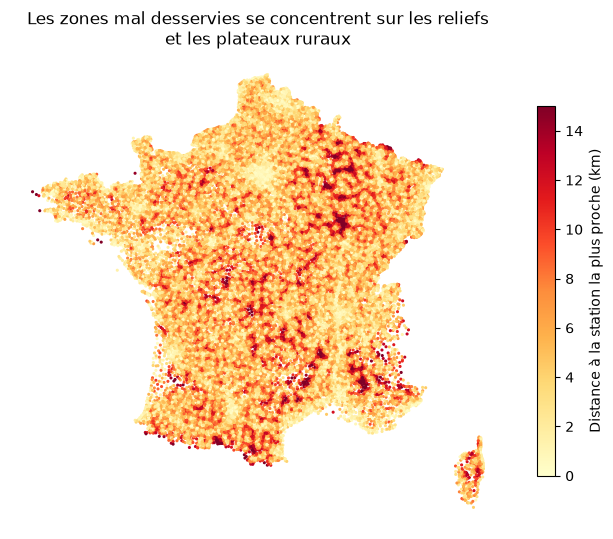

In [14]:
fig, ax = plt.subplots(figsize=(8, 8))

nuage = ax.scatter(
    df_communes["longitude"], df_communes["latitude"],
    c=df_communes["distance_station_km"],
    cmap="YlOrRd", s=1.5, vmin=0, vmax=15,
)
fig.colorbar(nuage, ax=ax, label="Distance à la station la plus proche (km)", shrink=0.6)

ax.set_aspect(1 / np.cos(np.radians(46.5)))
ax.set_axis_off()
ax.set_title("Les zones mal desservies se concentrent sur les reliefs\net les plateaux ruraux")
plt.show()

## 5. Prix : comparaison brute


On définit le prix moyen d'une station en choisissant le gazole car il est le plus répandu. On associe à chaque commune le prix du gazole dans la station la plus proche. La proportion de communes sans prix est la même pour les déserts que pour les autres donc il n'y a pas de biais de sélection. Enfin, on trouve que l'écart est de 1,2 centime par litre. L'hypothèse selon laquelle les habitants des déserts de carburant paient plus cher ne se vérifie donc pas sur ces données. 

In [15]:
prix_moyen_station = (
    df_prix[df_prix["carburant"] == "Gazole"]
    .groupby("id")["valeur"]
    .mean()
)

df_communes["prix_gazole"] = df_communes["station_proche_id"].map(prix_moyen_station)

print("Communes sans prix gazole :", df_communes["prix_gazole"].isna().sum())
print(df_communes.groupby("est_desert")["prix_gazole"].agg(["count", "mean", "median"]))

Communes sans prix gazole : 6836
            count      mean  median
est_desert                         
False       26291  2.109718   2.089
True         1619  2.122322   2.099


Les boîtes se recouvrent presque entièrement : l'écart est économiquement négligeable.

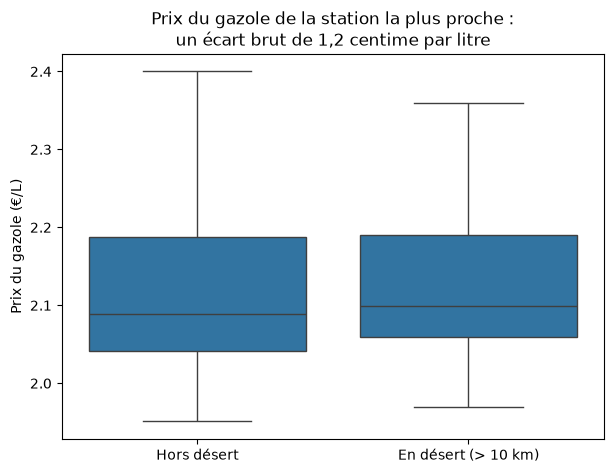

In [16]:
fig, ax = plt.subplots(figsize=(7, 5))

sns.boxplot(
    data=df_communes.dropna(subset=["prix_gazole"]),
    x="est_desert", y="prix_gazole", ax=ax, showfliers=False,
)
ax.set_xticks([0, 1], ["Hors désert", "En désert (> 10 km)"])
ax.set(xlabel="", ylabel="Prix du gazole (€/L)",
       title="Prix du gazole de la station la plus proche :\nun écart brut de 1,2 centime par litre")
plt.show()

## 6. Écart normalisé par département

La comparaison brute mélange les niveaux de prix régionaux. On compare donc le prix de chaque station à la
**médiane départementale** du même carburant (`add_departement_gap`), ce qui isole l'écart local du niveau
général du département.

In [17]:
gazole = (df_prix[df_prix['carburant'] == 'Gazole'][['id', 'valeur']]
          .rename(columns={'id': 'station_id', 'valeur': 'prix'})
          .merge(df_stations[['id', 'departement']].rename(columns={'id': 'station_id', 'departement': 'dep'}),
                 on='station_id'))
gazole['carburant'] = 'Gazole'
gazole = add_departement_gap(gazole, dep_col='dep')
ecart_station = gazole.groupby('station_id')['ecart_dep'].mean()
print(f"Stations avec un prix gazole retenu : {len(ecart_station)}")

df_communes['ecart_station'] = df_communes['station_proche_id'].map(ecart_station)
print(f"Communes sans prix gazole (station la plus proche) : {df_communes['ecart_station'].isna().mean():.1%}")
comparaison = (df_communes.dropna(subset=['ecart_station']).groupby('est_desert')['ecart_station']
               .agg(['count', 'median', 'mean']))
comparaison[['median', 'mean']] *= 100
display(comparaison.round(2))

Stations avec un prix gazole retenu : 8252
Communes sans prix gazole (station la plus proche) : 19.7%


,count,median,mean
est_desert,,,
False,26291,0.15,2.47
True,1619,0.70,2.19


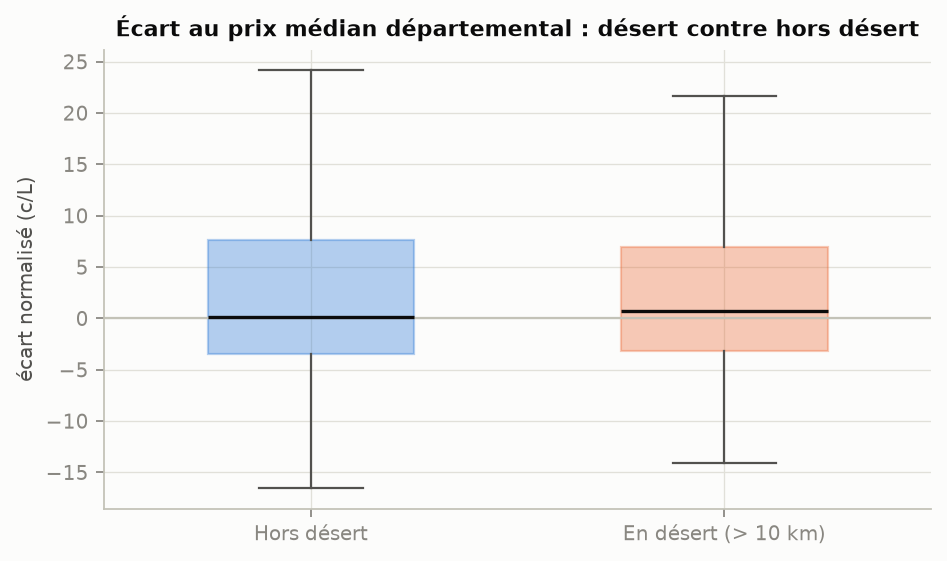

In [18]:
from carburants import viz  # fixe le backend de figure ; l'affichage inline est rétabli en fin de cellule
groupes = {
    'Hors désert': df_communes.loc[~df_communes['est_desert'], 'ecart_station'].dropna().to_numpy() * 100,
    'En désert (> 10 km)': df_communes.loc[df_communes['est_desert'], 'ecart_station'].dropna().to_numpy() * 100,
}
fig = viz.boxplot_groupes(groupes, label='écart normalisé (c/L)',
                          title='Écart au prix médian départemental : désert contre hors désert')
chemin = C.FIGURES_DIR / 'collectif_01_ecart_desert.png'
viz.save_figure(fig, chemin)
display(Image(filename=str(chemin), width=520))
%matplotlib inline

## 7. La concurrence locale fait-elle le prix à la pompe ?

L'unité d'observation est **la station**. C'est à ce niveau que le prix est fixé, et c'est à ce niveau que varient les
variables qui nous intéressent : nombre de concurrents, enseigne, accès autoroutier, distance au supermarché. Régresser
sur les communes reviendrait à répéter chaque prix autant de fois que la station est la plus proche d'une commune —
environ 3,4 fois en moyenne — et les erreurs-types, corrigées de l'hétéroscédasticité mais pas de cette répétition,
sous-estimeraient la variance d'un facteur proche de $\sqrt{3{,}4} \approx 1{,}8$.

La commune reste utile pour décrire **ce que chaque station dessert**. Pour chaque station, on agrège les communes dont
elle est la station la plus proche, ce qui donne la population desservie, la densité moyenne pondérée par la population,
et le fait de desservir au moins une commune en désert.

Deux lectures sont possibles, et elles ne répondent pas à la même question :

- **sans pondération**, chaque station compte pour une : on décrit le marché de détail ;
- **pondérée par la population desservie**, chaque habitant compte pour un : on décrit le prix que voit la population.
  Les stations qui ne sont la plus proche d'aucune commune sortent de cette seconde lecture.

Quatre modèles emboîtés expliquent l'écart au prix médian départemental du gazole :

- **M0** : concurrence ($\ln(1 + n)$ concurrents à 5 km), famille d'enseigne, autoroute ;
- **M1** : M0 + densité de la population desservie ;
- **M2** : M1 + distance au supermarché le plus proche ;
- **M3** : M2 + desservir un désert (> 10 km), pour confronter la question des déserts à celle de la concurrence.

Si le coefficient de concurrence reste stable de M0 à M3, il n'est pas un artefact de la densité ni de la distance aux
grandes surfaces. Erreurs-types HC1 ; le $R^2$, pondéré le cas échéant, est donné pour chaque modèle.

Deux précautions. La modalité `inconnu` de l'enseigne n'est pas un type de station mais un **défaut d'appariement** du
cache OpenStreetMap : elle est nommée comme telle dans les tableaux, et un modèle de robustesse réestime M3 sur les
seules stations appariées. Par ailleurs la distance au supermarché et le fait d'être une station de grande distribution
se recouvrent largement — une station de grande surface est à quelques dizaines de mètres d'un supermarché par
construction — ce que le diagnostic ci-dessous quantifie avant toute interprétation du coefficient.

In [19]:
grandes_surfaces = pd.read_parquet(C.GS_PARQUET)  # déjà filtrée (magasins bio exclus) par le pipeline
print(f"Grandes surfaces retenues (OSM, magasins bio exclus) : {len(grandes_surfaces)}")

stations_df = (df_stations
               .rename(columns={'id': 'station_id', 'latitude': 'lat', 'longitude': 'lon'})
               .drop_duplicates('station_id'))
dist_station_gs = distance_grande_surface(stations_df, grandes_surfaces).drop_duplicates('station_id')

# Un prix par station : une station peut porter plusieurs lignes de prix gazole.
prix_station = gazole.groupby('station_id')['prix'].mean()

stations_gazole = (stations_df[['station_id', 'lat', 'lon', 'type_route']]
                   .merge(prix_station.rename('prix'), left_on='station_id', right_index=True))
concurrence = fuel_competition(stations_gazole[['station_id', 'lat', 'lon', 'prix']])
enseigne = (pd.read_parquet(C.OSM_MATCH_PARQUET)[['station_id', 'famille_enseigne']]
            .drop_duplicates('station_id').set_index('station_id')['famille_enseigne'])

attributs = (concurrence.drop_duplicates('station_id').set_index('station_id')[['n_concurrents_5km']]
             .join(stations_gazole.set_index('station_id')[['type_route']])
             .join(enseigne)
             .join(dist_station_gs.set_index('station_id')[['dist_grande_surface_km']]))

Grandes surfaces retenues (OSM, magasins bio exclus) : 15216


In [20]:
# Ce que chaque station dessert : les communes sont agrégées sur leur station la
# plus proche. Une station peut n'être la plus proche d'aucune commune ; sa
# population desservie vaut alors 0 et elle sort de la lecture pondérée.
d = df_communes.dropna(subset=['station_proche_id']).copy()
d['_pop_densite'] = d['population'] * d['densite']
d['_pop_desert'] = d['population'] * d['est_desert'].astype(float)

desserte = d.groupby('station_proche_id').agg(
    pop_desservie=('population', 'sum'),
    n_communes_desservies=('code', 'size'),
    dessert_desert=('est_desert', 'max'),
    _pop_densite=('_pop_densite', 'sum'),
    _pop_desert=('_pop_desert', 'sum'),
)
_pop = desserte['pop_desservie'].replace(0, np.nan)
desserte['densite_desservie'] = desserte['_pop_densite'] / _pop
desserte['part_pop_desert'] = desserte['_pop_desert'] / _pop
desserte = desserte.drop(columns=['_pop_densite', '_pop_desert'])
desserte.index.name = 'station_id'

# Densité de repli pour les stations qui ne desservent aucune commune : celle de
# la commune dont le centre est le plus proche de la station.
_, idx_commune = nearest_k(stations_df['lat'].values, stations_df['lon'].values,
                           df_communes['latitude'].values, df_communes['longitude'].values, k=1)
densite_commune_proche = pd.Series(df_communes['densite'].to_numpy()[idx_commune[:, 0]],
                                   index=stations_df['station_id'].to_numpy())

s = (ecart_station.rename('ecart').to_frame()
     .join(attributs, how='inner')
     .join(desserte, how='left'))
s['pop_desservie'] = s['pop_desservie'].fillna(0.0)
s['n_communes_desservies'] = s['n_communes_desservies'].fillna(0).astype(int)
s['dessert_desert'] = s['dessert_desert'].fillna(False).astype(float)
s['densite_desservie'] = s['densite_desservie'].fillna(densite_commune_proche.reindex(s.index))
s['log_densite'] = np.log1p(s['densite_desservie'])

avant = len(s)
s = s.dropna(subset=['n_concurrents_5km', 'famille_enseigne', 'type_route',
                     'dist_grande_surface_km', 'log_densite'])
print(f"Stations retenues pour les modeles : {len(s)} sur {avant}")
print(f"  dont station la plus proche d'aucune commune : {(s['pop_desservie'] == 0).sum()}")
print(f"  population couverte : {100 * s['pop_desservie'].sum() / df_communes['population'].sum():.1f} %")
print("Les stations apparues depuis le cache OpenStreetMap n'ont pas d'enseigne : elles sont exclues.")

# Diagnostic 1 : support de la variable de concurrence, avant toute lecture
# du type « de 0 a 10 concurrents ».
print("\nConcurrents a 5 km, quantiles :")
print(s['n_concurrents_5km'].quantile([0, .1, .25, .5, .75, .9, .99, 1]).round(1).to_string())

# Diagnostic 2 : recouvrement entre distance au supermarche et famille d'enseigne.
print("\nDistance au supermarche le plus proche, par famille d'enseigne (km) :")
print(s.groupby('famille_enseigne')['dist_grande_surface_km']
      .describe()[['count', '25%', '50%', '75%']].round(2).to_string())

Stations retenues pour les modeles : 8249 sur 8252
  dont station la plus proche d'aucune commune : 2160
  population couverte : 87.2 %
Les stations apparues depuis le cache OpenStreetMap n'ont pas d'enseigne : elles sont exclues.

Concurrents a 5 km, quantiles :
0.00     0.0
0.10     0.0
0.25     1.0
0.50     3.0
0.75     8.0
0.90    15.0
0.99    32.0
1.00    42.0

Distance au supermarche le plus proche, par famille d'enseigne (km) :
                      count   25%   50%   75%
famille_enseigne                             
autre                 412.0  0.10  0.36  2.28
grande_distribution  3634.0  0.07  0.12  0.19
inconnu              1425.0  0.21  0.47  1.29
independant           443.0  0.19  0.57  2.19
petrolier            2335.0  0.28  0.61  1.36


In [21]:
def variables(d):
    return pd.DataFrame({
        'concurrence (ln(1 + n))': np.log1p(d['n_concurrents_5km']),
        'grande distribution': (d['famille_enseigne'] == 'grande_distribution').astype(float),
        'indépendant': (d['famille_enseigne'] == 'independant').astype(float),
        'enseigne non appariée (OSM)': (d['famille_enseigne'] == 'inconnu').astype(float),
        'autre enseigne': (d['famille_enseigne'] == 'autre').astype(float),
        'autoroute': (d['type_route'] == 'A').astype(float),
        'densité desservie (ln(1 + hab/km²))': d['log_densite'],
        'distance supermarché (ln(1 + km))': np.log1p(d['dist_grande_surface_km']),
        'dessert un désert (> 10 km)': d['dessert_desert'],
    }, index=d.index)


M0 = ['concurrence (ln(1 + n))', 'grande distribution', 'indépendant',
      'enseigne non appariée (OSM)', 'autre enseigne', 'autoroute']
M1 = M0 + ['densité desservie (ln(1 + hab/km²))']
M2 = M1 + ['distance supermarché (ln(1 + km))']
M3 = M2 + ['dessert un désert (> 10 km)']


def estimer(colonnes, echantillon=None, poids=None):
    """MCO (ou MCP si `poids`) avec erreurs-types HC1. Coefficients en c/L.

    La pondération passe par la transformation (y, X) -> (sqrt(w) y, sqrt(w) X) :
    les MCO sur les données transformées donnent l'estimateur des MCP, et le
    sandwich HC1 sur ces mêmes données donne sa variance robuste. Les poids sont
    normalisés en moyenne pour ne pas perturber le facteur n/(n-k) de HC1.
    """
    d = s if echantillon is None else s.loc[echantillon]
    X = variables(d)[colonnes]
    X = X.loc[:, X.std() > 0]          # retire une modalité absente du sous-échantillon
    X.insert(0, 'constante', 1.0)
    y = d['ecart'].to_numpy(dtype=float)
    Xm = X.to_numpy(dtype=float)

    if poids is None:
        w = np.ones(len(d))
    else:
        w = poids.reindex(d.index).to_numpy(dtype=float)
        garde = np.isfinite(w) & (w > 0)
        y, Xm, w = y[garde], Xm[garde], w[garde]
        w = w / w.mean()
    racine = np.sqrt(w)

    res = ols_hc1(y * racine, Xm * racine[:, None], list(X.columns)).set_index('variable')
    res[['coef', 'ecart_type_hc1']] *= 100     # €/L -> centimes/L

    beta = res['coef'].to_numpy() / 100
    residus = y - Xm @ beta
    moyenne = np.average(y, weights=w)
    r2 = 1 - (w * residus ** 2).sum() / (w * (y - moyenne) ** 2).sum()
    return res, r2, int(w.size)


resultats = {nom: estimer(cols) for nom, cols in [('M0', M0), ('M1', M1), ('M2', M2), ('M3', M3)]}
# Robustesse : M3 pondéré par la population desservie, puis M3 sur les seules
# stations dont l'enseigne est appariée (la modalité `inconnu` disparaît d'elle-même).
resultats['M3 pop.'] = estimer(M3, poids=s['pop_desservie'])
resultats['M3 appar.'] = estimer(M3, echantillon=s['famille_enseigne'] != 'inconnu')


def tableau(noms):
    lignes = {}
    for nom in noms:
        res, r2, n = resultats[nom]
        for var in res.index:
            lignes.setdefault(var, {})[nom] = f"{res.loc[var, 'coef']:+.2f} c (t = {res.loc[var, 't']:.1f})"
        lignes.setdefault('R²', {})[nom] = f"{r2:.3f}"
        lignes.setdefault('stations', {})[nom] = str(n)
    ordre = [v for v in ['constante'] + M3 if v in lignes] + ['R²', 'stations']
    return pd.DataFrame(lignes).T.reindex(ordre).loc[:, noms].fillna('—')


print("Modèles emboîtés — une station = une observation")
display(tableau(['M0', 'M1', 'M2', 'M3']))

print("Robustesse — pondération par la population desservie, puis stations appariées seulement")
display(tableau(['M3', 'M3 pop.', 'M3 appar.']))

Modèles emboîtés — une station = une observation


,M0,M1,M2,M3
constante,+8.70 c (t = 35.6),+8.82 c (t = 22.0),+6.42 c (t = 14.7),+6.72 c (t = 14.8)
concurrence (ln(1 + n)),-1.73 c (t = -20.6),-1.69 c (t = -12.8),-1.48 c (t = -11.3),-1.49 c (t = -11.3)
grande distribution,-8.46 c (t = -40.7),-8.46 c (t = -40.7),-7.54 c (t = -34.1),-7.55 c (t = -34.1)
indépendant,+3.13 c (t = 7.9),+3.12 c (t = 7.9),+3.25 c (t = 8.2),+3.27 c (t = 8.3)
enseigne non appariée (OSM),-5.25 c (t = -18.4),-5.25 c (t = -18.3),-5.00 c (t = -17.6),-5.00 c (t = -17.6)
autre enseigne,-2.37 c (t = -5.2),-2.38 c (t = -5.2),-2.25 c (t = -5.1),-2.23 c (t = -5.0)
autoroute,+10.48 c (t = 21.9),+10.46 c (t = 21.8),+9.16 c (t = 18.7),+9.09 c (t = 18.6)
densité desservie (ln(1 + hab/km²)),—,-0.03 c (t = -0.4),+0.10 c (t = 1.2),+0.06 c (t = 0.7)
distance supermarché (ln(1 + km)),—,—,+2.01 c (t = 12.8),+2.02 c (t = 12.9)
dessert un désert (> 10 km),—,—,—,-0.78 c (t = -2.8)


Robustesse — pondération par la population desservie, puis stations appariées seulement


,M3,M3 pop.,M3 appar.
constante,+6.72 c (t = 14.8),-2.17 c (t = -0.6),+7.74 c (t = 16.3)
concurrence (ln(1 + n)),-1.49 c (t = -11.3),-2.21 c (t = -5.4),-1.77 c (t = -12.7)
grande distribution,-7.55 c (t = -34.1),-6.70 c (t = -8.9),-8.00 c (t = -35.6)
indépendant,+3.27 c (t = 8.3),+4.87 c (t = 4.7),+3.21 c (t = 8.2)
enseigne non appariée (OSM),-5.00 c (t = -17.6),-3.93 c (t = -4.8),—
autre enseigne,-2.23 c (t = -5.0),+13.95 c (t = 2.0),-2.44 c (t = -5.4)
autoroute,+9.09 c (t = 18.6),+9.62 c (t = 8.5),+8.52 c (t = 16.4)
densité desservie (ln(1 + hab/km²)),+0.06 c (t = 0.7),+1.56 c (t = 2.8),+0.05 c (t = 0.6)
distance supermarché (ln(1 + km)),+2.02 c (t = 12.9),+2.00 c (t = 5.5),+1.42 c (t = 8.4)
dessert un désert (> 10 km),-0.78 c (t = -2.8),+0.80 c (t = 1.1),-0.86 c (t = -2.9)


## 8. Grandes surfaces : la distance au supermarché

Les grandes surfaces viennent du cache OpenStreetMap (`shop=supermarket`, magasins bio exclus). OpenStreetMap
ne distingue pas hypermarchés et supermarchés. Le tableau ci-dessous mesure la **liaison** entre la distance au supermarché
et l'écart de prix ; il ne mesure pas l'endroit où les habitants font leur plein.

In [22]:
pop = df_communes['population']
d_gs, _ = nearest_k(df_communes['latitude'].values, df_communes['longitude'].values,
                    grandes_surfaces['lat'].values, grandes_surfaces['lon'].values, k=1)
df_communes['distance_grande_surface_km'] = d_gs[:, 0] / 1000
tab_gs = part_population_dans_rayon(df_communes['distance_grande_surface_km'], pop, seuils_km=[1, 5, 10])
display(tab_gs.round(3))

ecarts_gs = gazole.merge(dist_station_gs, on='station_id')
tranches = pd.cut(ecarts_gs['dist_grande_surface_km'], [-np.inf, 1, 3, 5, 10, np.inf],
                  labels=['≤ 1 km', '1–3 km', '3–5 km', '5–10 km', '> 10 km'])
tab_gs_tranches = (ecarts_gs.groupby(tranches, observed=True)['ecart_dep']
                   .agg(['count', 'median']).assign(mediane_c=lambda t: 100 * t['median']).round(2))
display(tab_gs_tranches)

,seuil_km,part_population,part_communes
0,1,0.510,0.073
1,5,0.878,0.496
2,10,0.983,0.900


,count,median,mediane_c
dist_grande_surface_km,,,
≤ 1 km,6440,-0.01,-1.00
1–3 km,930,0.06,5.70
3–5 km,349,0.10,10.10
5–10 km,393,0.10,9.55
> 10 km,140,0.06,6.00


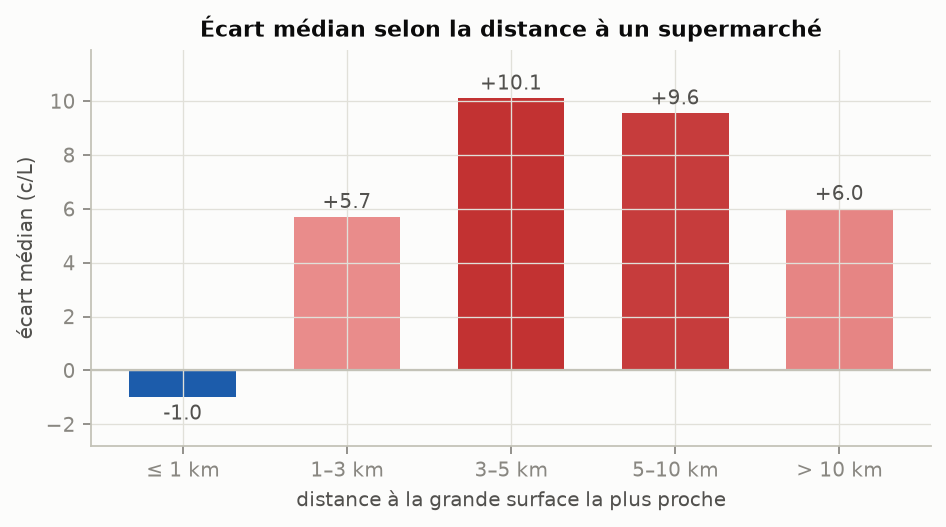

In [23]:
from carburants import viz
tranches_figure = pd.DataFrame({'tranche': tab_gs_tranches.index.astype(str),
                                'mediane_c': tab_gs_tranches['mediane_c'].to_numpy()})
fig = viz.barres_ecart_tranches(tranches_figure, label='distance à la grande surface la plus proche',
                                titre='Écart médian selon la distance à un supermarché')
chemin = C.FIGURES_DIR / 'collectif_02_ecart_grande_surface.png'
viz.save_figure(fig, chemin)
display(Image(filename=str(chemin), width=520))
%matplotlib inline

## 9. Population pondérée

Une médiane **par commune** décrit une commune typique. Une médiane **pondérée par la population** décrit un habitant typique.
Les deux diffèrent parce que les communes éloignées sont en grande partie peu peuplées.

In [24]:
dist = df_communes['distance_station_km']
print(f"Distance médiane par commune : {dist.median():.2f} km")
print(f"Distance médiane pondérée par la population : {mediane_ponderee(dist, pop):.2f} km")
tab_population = part_population_dans_rayon(dist, pop, seuils_km=[1, 5, 10])
display(tab_population.round(3))

Distance médiane par commune : 4.65 km
Distance médiane pondérée par la population : 1.21 km


,seuil_km,part_population,part_communes
0,1,0.421,0.070
1,5,0.892,0.547
2,10,0.990,0.940


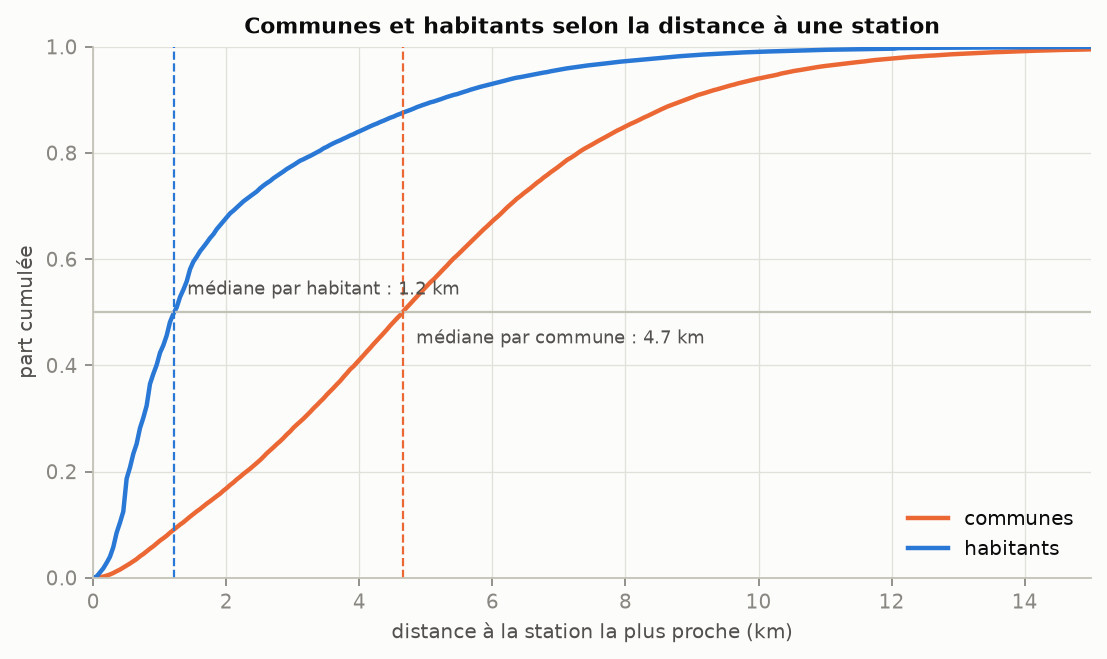

In [25]:
fig = viz.courbe_population_cumulee(df_communes['distance_station_km'], pop,
                                    label='distance à la station la plus proche (km)',
                                    titre='Communes et habitants selon la distance à une station')
chemin = C.FIGURES_DIR / 'collectif_03_courbe_population.png'
viz.save_figure(fig, chemin)
display(Image(filename=str(chemin), width=560))
%matplotlib inline

## 10. Niveau de vie

Le revenu médian communal (Filosofi 2023) est découpé en quartiles, et l'écart de prix de la station la plus
proche est comparé d'un quartile à l'autre. Le revenu a aussi été testé comme contrôle dans les modèles de la
section 7, sans effet visible.

In [26]:
revenus = pd.read_parquet(C.COMMUNES_PARQUET)[['code_commune', 'revenu_median_eur']]
r = (df_communes.merge(revenus, left_on='code', right_on='code_commune', how='left')
     .dropna(subset=['revenu_median_eur', 'ecart_station']))
r['quartile'] = pd.qcut(r['revenu_median_eur'], 4, labels=['Q1 (bas)', 'Q2', 'Q3', 'Q4 (haut)'])
tab_revenu = (r.groupby('quartile', observed=True)['ecart_station']
              .agg(['count', 'median']).assign(mediane_c=lambda t: 100 * t['median']).round(2))
display(tab_revenu)

,count,median,mediane_c
quartile,,,
Q1 (bas),6244,0.01,1.0
Q2,6238,0.01,0.8
Q3,6202,0.00,0.0
Q4 (haut),6227,0.00,0.0


La médiane décroît de manière régulière avec la densité. On trouve un facteur six entre la distance médiane d'une densité inférieure à 6 et une densité supérieure à 300 habitants par km².

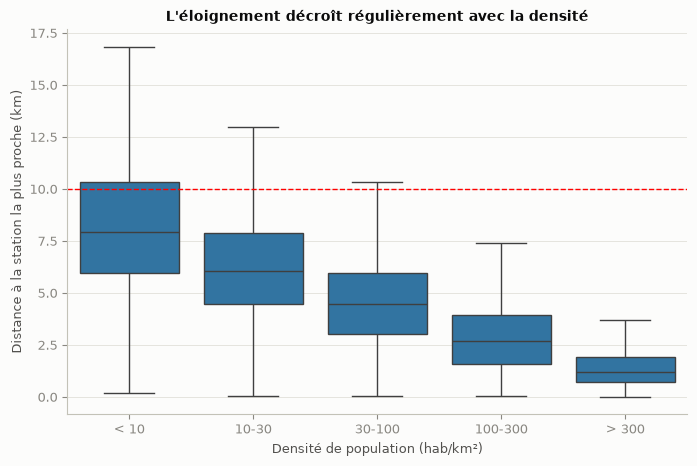

In [27]:
df_communes["classe_densite"] = pd.cut(
    df_communes["densite"],
    bins=[0, 10, 30, 100, 300, float("inf")],
    labels=["< 10", "10-30", "30-100", "100-300", "> 300"],
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df_communes, x="classe_densite", y="distance_station_km", ax=ax, showfliers=False)
ax.axhline(SEUIL_DESERT_KM, color="red", linestyle="--", linewidth=1)
ax.set(xlabel="Densité de population (hab/km²)", ylabel="Distance à la station la plus proche (km)",
       title="L'éloignement décroît régulièrement avec la densité")
plt.show()

In [28]:
par_departement = (
    df_communes
    .groupby("codeDepartement")
    .agg(
        distance_mediane=("distance_station_km", "median"),
        part_desert=("est_desert", "mean"),
        population=("population", "sum"),
        nb_communes=("code", "size"),
    )
    .sort_values("distance_mediane", ascending=False)
)
par_departement["part_desert"] = (100 * par_departement["part_desert"]).round(1)

print("Les 10 départements les plus éloignés :")
print(par_departement.head(10))
print("\nLes 5 mieux desservis :")
print(par_departement.tail(5))

Les 10 départements les plus éloignés :
                 distance_mediane  part_desert  population  nb_communes
codeDepartement                                                        
55                       6.839669         20.4    180290.0          499
36                       6.748798         12.9    216069.0          241
52                       6.571291         19.7    168331.0          426
09                       6.562421         15.1    155722.0          325
23                       6.554302         18.8    115527.0          255
15                       6.335119         17.2    144196.0          250
48                       6.288670         21.1     76486.0          152
32                       6.213430          8.7    192645.0          458
2B                       6.208393         15.7    187180.0          236
03                       6.193944         11.0    333298.0          317

Les 5 mieux desservis :
                 distance_mediane  part_desert  population  nb_communes

Sans surprise, la diagonale du vide apparaît le plus dans les départements les plus éloignés, mais d'autres aussi comme l'Ariège ou la Lozère. On trouve notamment un facteur 14 entre la Meuse et Paris. La Lozère montre la plus forte part de communes en désert (21,1 %) sans avoir la distance médiane la plus élevée. Autrement dit, sa distribution est plus contrastée que celle des départements de la diagonale du vide. Le relief y crée des ruptures d'accès localisées, tandis que le dépeuplement produit un éloignement plus uniforme.

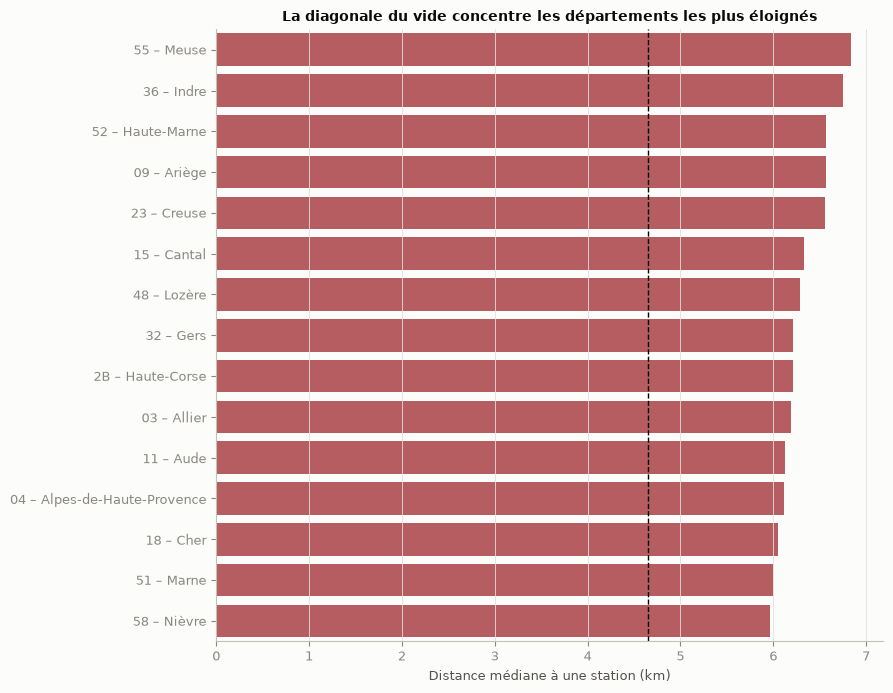

In [29]:
noms_departements = pd.json_normalize(
    requests.get("https://geo.api.gouv.fr/departements?fields=code,nom", timeout=60).json()
).set_index("code")["nom"]

top15 = par_departement.head(15).copy()
top15["libelle"] = top15.index + " – " + top15.index.map(noms_departements)

fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(x=top15["distance_mediane"], y=top15["libelle"], ax=ax, color="#C44E52")

mediane_nationale = df_communes["distance_station_km"].median()
ax.axvline(mediane_nationale, color="black", linestyle="--", linewidth=1)
ax.annotate(
    "Médiane nationale", xy=(mediane_nationale, 14.6),
    xytext=(4, 0), textcoords="offset points", fontsize=9, va="center",
)

ax.set(xlabel="Distance médiane à une station (km)", ylabel="",
       title="La diagonale du vide concentre les départements les plus éloignés")
fig.tight_layout()
plt.show()

## 11. Dimension temporelle

Une analyse dans le temps demande des captures répétées du flux de prix. Le diagnostic ci-dessous indique si le
seuil retenu est atteint (24 captures sur 72 h). Tant qu'il ne l'est pas, aucune conclusion temporelle n'est tirée.

In [30]:
snap = load_snapshot_prices(storage_from_env(C.SNAPSHOT_DIR))
couverture = snapshot_coverage(snap)
ok, message_temporel = temporal_feasibility(couverture)
print(f"Captures : {couverture['n_captures']} sur {couverture['duree_heures']:.1f} h")
print(message_temporel)

Captures : 0 sur 0.0 h
Aucune capture horaire n'a été collectée : aucune analyse temporelle n'est possible ; les résultats sont une coupe transversale unique.


## 12. Conclusion et limites

In [31]:
def fr(x, nd=1):
    """Nombre au format français."""
    return f"{x:,.{nd}f}".replace(",", " ").replace(".", ",")

def coef(modele, variable):
    return resultats[modele][0].loc[variable, 'coef']

def tstat(modele, variable):
    res = resultats[modele][0]
    return res.loc[variable, 'coef'] / res.loc[variable, 'ecart_type_hc1']

conc = 'concurrence (ln(1 + n))'
modeles = ['M0', 'M1', 'M2', 'M3']
effet_0_10_M0 = coef('M0', conc) * np.log(11)   # de 0 à 10 concurrents, en c/L
effet_0_10_M3 = coef('M3', conc) * np.log(11)
baisse_M1_M2 = 1 - coef('M2', conc) / coef('M1', conc)  # part de l'effet qui disparaît avec la distance au supermarché
autoroutes = [coef(m, 'autoroute') for m in modeles]
gds = [coef(m, 'grande distribution') for m in modeles]
t_conc = [tstat(m, conc) for m in modeles]
r2_m3 = resultats['M3'][1]
n_m3 = resultats['M3'][2]

# Médianes brutes de la section 6, déjà exprimées en centimes par litre.
brut_desert = comparaison.loc[True, 'median']
brut_hors = comparaison.loc[False, 'median']

# Lecture pondérée par la population desservie, pour comparaison.
conc_pop = coef('M3 pop.', conc)
conc_appar = coef('M3 appar.', conc)

display(Markdown(f"""
### Question 1 : où sont les déserts, et les habitants y paient-ils plus cher ?

À 10 km à vol d'oiseau, {fr(part_communes)} % des communes sont en désert, soit {fr(part_pop)} % de la population
({fr(pop_desert, 0)} habitants). Une commune typique est à {fr(dist.median())} km d'une station ; un habitant typique à
{fr(mediane_ponderee(dist, pop))} km.

Les déserts ne paient pas plus cher, mais le signe dépend de ce qu'on tient fixe. En brut, l'écart médian au prix médian
départemental est un peu *plus élevé* dans les communes en désert ({fr(brut_desert, 2)} c/L contre {fr(brut_hors, 2)} c/L).
Conditionnellement à l'enseigne, à l'autoroute, à la densité desservie et à la distance au supermarché, le signe s'inverse :
une station qui dessert au moins une commune en désert affiche {fr(coef('M3', 'dessert un désert (> 10 km)'), 2)} c/L
(t = {fr(tstat('M3', 'dessert un désert (> 10 km)'))}). Autrement dit, le surcoût apparent des déserts est un **effet de
composition du parc** — on y trouve moins de stations de grande distribution — et non une rente de captivité.

Le coût des déserts reste donc un coût de trajet : un aller-retour de 20 km consomme environ 1,2 L sur une base de
6 L/100 km, soit {fr(1.2 * df_communes['prix_gazole'].mean(), 2)} € de carburant par plein, sans compter le temps.

### Question 2 : la concurrence locale fait-elle le prix à la pompe ?

Oui, mais peu. Plus une station a de concurrents à 5 km, plus son prix est bas : passer de 0 à 10 concurrents correspond à
une baisse d'environ {fr(-effet_0_10_M0)} c/L dans M0 et de {fr(-effet_0_10_M3)} c/L dans M3. L'effet reste négatif et
significatif de M0 à M3 (t entre {fr(t_conc[0])} et {fr(t_conc[3])}), sur {n_m3} stations. Il tient aux deux variantes de
robustesse : {fr(conc_pop, 2)} c/L une fois pondéré par la population desservie, {fr(conc_appar, 2)} c/L sur les seules
stations dont l'enseigne est appariée, contre {fr(coef('M3', conc), 2)} c/L dans M3.

L'effet n'est pas indépendant de la distance aux grandes surfaces : son coefficient baisse d'environ
{fr(100 * baisse_M1_M2, 0)} % quand on ajoute cette distance (M2). À concurrence égale, les stations qui desservent une
population plus dense affichent un écart un peu plus élevé
({'+' if coef('M3', 'densité desservie (ln(1 + hab/km²))') >= 0 else ''}{fr(coef('M3', 'densité desservie (ln(1 + hab/km²))'), 2)} c/L par ln(1 + hab/km²)).

Ce qui pèse beaucoup plus que la concurrence : l'autoroute ({fr(min(autoroutes))} à {fr(max(autoroutes))} c/L selon le
modèle) et la grande distribution ({fr(max(gds))} à {fr(min(gds))} c/L, par rapport aux pétroliers). La modalité
« enseigne non appariée » porte un coefficient du même ordre ({fr(coef('M3', 'enseigne non appariée (OSM)'))} c/L), mais
elle ne décrit aucun type de station : elle mesure un défaut d'appariement du cache OpenStreetMap, et son signe négatif
indique que les stations non appariées sont plutôt parmi les moins chères. Le modèle « M3 appar. » vérifie que les autres
coefficients ne tiennent pas à elle. Avec un R² de {fr(r2_m3, 2)} dans M3, une grande part des écarts reste non expliquée :
demande, état de la station, moment des mises à jour.

### Ce qui reste à dire sur la distance aux supermarchés

Les stations éloignées d'un supermarché sont plus chères : +{fr(coef('M3', 'distance supermarché (ln(1 + km))'), 2)} c/L
par ln(1 + km) dans M2 et M3. Mais cette variable recoupe en partie le fait d'être une station de grande distribution,
qui est à quelques dizaines de mètres d'un supermarché par construction (voir le diagnostic de la section 7) : le
coefficient ne s'interprète qu'avec cette réserve. Les médianes par tranche de distance (section 8) augmentent nettement entre « ≤ 1 km » et « 1–3 km », puis se stabilisent : la relation n'est pas linéaire en ln(1 + km), et le coefficient n'en résume qu'une partie. Le lien est mesuré ; l'hypothèse que les habitants font leur plein au supermarché ne l'est pas.

### Limites

- **Corrélations, pas effets causaux.** Les modèles décrivent des liaisons conditionnelles. Le nombre de concurrents
  dépend lui-même des conditions locales de marché.
- **Unité d'observation** : la station. La commune n'entre que par la population et la densité desservies, agrégées sur
  la station la plus proche ; cette affectation suppose que les habitants se servent à la station la plus proche.
- **Distance à vol d'oiseau**, mesurée depuis le centre de la commune.
- **Une seule journée de flux** : les coefficients bougent d'un jour à l'autre ; le signe et l'ordre de grandeur restent
  les mêmes.
- **Enseignes** issues d'un cache OpenStreetMap ; les stations apparues depuis en sont absentes et sortent des modèles.
- **Grandes surfaces** : OpenStreetMap ne distingue pas hypermarchés et supermarchés.
- **Revenu** : données de 2023, prix d'aujourd'hui ; effet nul ici.

### Dimension temporelle

{message_temporel}
"""))


### Question 1 : où sont les déserts, et les habitants y paient-ils plus cher ?

À 10 km à vol d'oiseau, 6,0 % des communes sont en désert, soit 1,0 % de la population
(636 124 habitants). Une commune typique est à 4,7 km d'une station ; un habitant typique à
1,2 km.

Les déserts ne paient pas plus cher, mais le signe dépend de ce qu'on tient fixe. En brut, l'écart médian au prix médian
départemental est un peu *plus élevé* dans les communes en désert (0,70 c/L contre 0,15 c/L).
Conditionnellement à l'enseigne, à l'autoroute, à la densité desservie et à la distance au supermarché, le signe s'inverse :
une station qui dessert au moins une commune en désert affiche -0,78 c/L
(t = -2,8). Autrement dit, le surcoût apparent des déserts est un **effet de
composition du parc** — on y trouve moins de stations de grande distribution — et non une rente de captivité.

Le coût des déserts reste donc un coût de trajet : un aller-retour de 20 km consomme environ 1,2 L sur une base de
6 L/100 km, soit 2,53 € de carburant par plein, sans compter le temps.

### Question 2 : la concurrence locale fait-elle le prix à la pompe ?

Oui, mais peu. Plus une station a de concurrents à 5 km, plus son prix est bas : passer de 0 à 10 concurrents correspond à
une baisse d'environ 4,2 c/L dans M0 et de 3,6 c/L dans M3. L'effet reste négatif et
significatif de M0 à M3 (t entre -20,6 et -11,3), sur 8249 stations. Il tient aux deux variantes de
robustesse : -2,21 c/L une fois pondéré par la population desservie, -1,77 c/L sur les seules
stations dont l'enseigne est appariée, contre -1,49 c/L dans M3.

L'effet n'est pas indépendant de la distance aux grandes surfaces : son coefficient baisse d'environ
13 % quand on ajoute cette distance (M2). À concurrence égale, les stations qui desservent une
population plus dense affichent un écart un peu plus élevé
(+0,06 c/L par ln(1 + hab/km²)).

Ce qui pèse beaucoup plus que la concurrence : l'autoroute (9,1 à 10,5 c/L selon le
modèle) et la grande distribution (-7,5 à -8,5 c/L, par rapport aux pétroliers). La modalité
« enseigne non appariée » porte un coefficient du même ordre (-5,0 c/L), mais
elle ne décrit aucun type de station : elle mesure un défaut d'appariement du cache OpenStreetMap, et son signe négatif
indique que les stations non appariées sont plutôt parmi les moins chères. Le modèle « M3 appar. » vérifie que les autres
coefficients ne tiennent pas à elle. Avec un R² de 0,35 dans M3, une grande part des écarts reste non expliquée :
demande, état de la station, moment des mises à jour.

### Ce qui reste à dire sur la distance aux supermarchés

Les stations éloignées d'un supermarché sont plus chères : +2,02 c/L
par ln(1 + km) dans M2 et M3. Mais cette variable recoupe en partie le fait d'être une station de grande distribution,
qui est à quelques dizaines de mètres d'un supermarché par construction (voir le diagnostic de la section 7) : le
coefficient ne s'interprète qu'avec cette réserve. Les médianes par tranche de distance (section 8) augmentent nettement entre « ≤ 1 km » et « 1–3 km », puis se stabilisent : la relation n'est pas linéaire en ln(1 + km), et le coefficient n'en résume qu'une partie. Le lien est mesuré ; l'hypothèse que les habitants font leur plein au supermarché ne l'est pas.

### Limites

- **Corrélations, pas effets causaux.** Les modèles décrivent des liaisons conditionnelles. Le nombre de concurrents
  dépend lui-même des conditions locales de marché.
- **Unité d'observation** : la station. La commune n'entre que par la population et la densité desservies, agrégées sur
  la station la plus proche ; cette affectation suppose que les habitants se servent à la station la plus proche.
- **Distance à vol d'oiseau**, mesurée depuis le centre de la commune.
- **Une seule journée de flux** : les coefficients bougent d'un jour à l'autre ; le signe et l'ordre de grandeur restent
  les mêmes.
- **Enseignes** issues d'un cache OpenStreetMap ; les stations apparues depuis en sont absentes et sortent des modèles.
- **Grandes surfaces** : OpenStreetMap ne distingue pas hypermarchés et supermarchés.
- **Revenu** : données de 2023, prix d'aujourd'hui ; effet nul ici.

### Dimension temporelle

Aucune capture horaire n'a été collectée : aucune analyse temporelle n'est possible ; les résultats sont une coupe transversale unique.
